# Elder Mist Round 2 — the visual RL lab

<div><span style="display:inline-block;background:#4C78A8;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">STATE</span><span style="display:inline-block;background:#0F766E;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">POLICY</span><span style="display:inline-block;background:#F58518;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ACTION</span><span style="display:inline-block;background:#B279A2;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">TRANSITION</span><span style="display:inline-block;background:#54A24B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">REWARD</span><span style="display:inline-block;background:#5B8FF9;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">S PRIME</span><span style="display:inline-block;background:#17BECF;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">OBSERVATION</span><span style="display:inline-block;background:#1F3A93;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">REPRESENTATION</span><span style="display:inline-block;background:#8B5CF6;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">EPISODE</span><span style="display:inline-block;background:#ECA82C;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">Q</span><span style="display:inline-block;background:#2F80ED;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">EXPLOIT</span><span style="display:inline-block;background:#334155;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ENVIRONMENT</span><span style="display:inline-block;background:#8C564B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">HISTORY</span><span style="display:inline-block;background:#A3A01B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">BELIEF</span></div>

This is the main lab.

You do **not** need Sea of Stars installed. We built a lightweight simulator around the strategically important structure of the second Elder Mist fight.

First you will play. Then rules will play. Then Q-learning will play.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-el0" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Elder Mist as an RL environment</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BATTLE STATE</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el0)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el0)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">MOVE</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el0)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#B279A2" stroke="#B279A2" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BOSS REACTS</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el0)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">REWARD</text>
</svg>
</div>


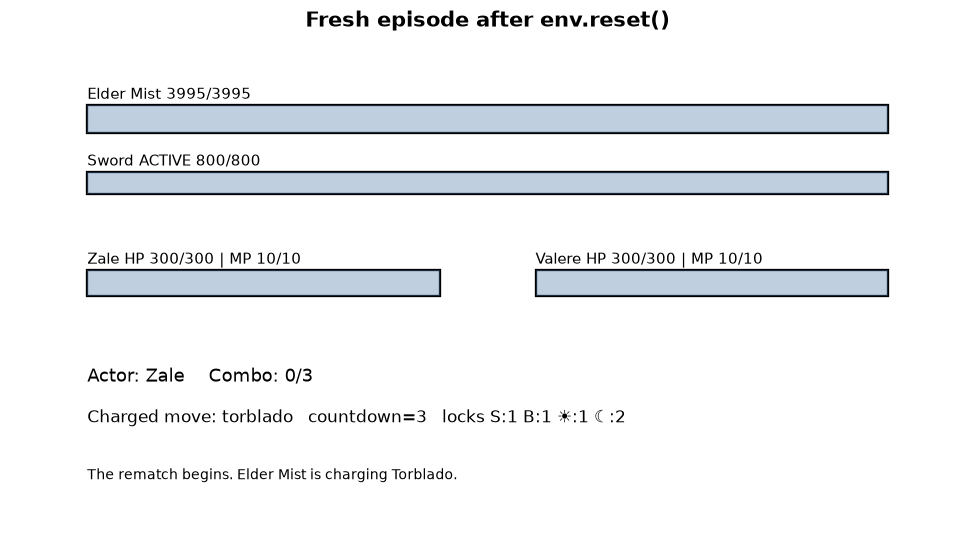

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

repo = Path.cwd()
if repo.name == "notebooks": repo = repo.parent
sys.path.insert(0, str(repo))
from visuals import COLORS

from eldermist import ElderMistReplicaEnv, ACTIONS, ACTION_TO_ID
from eldermist.policies import sensible_rule_policy, explain_sensible_rule_policy
from eldermist.qlearning import train_q, q_policy, explain_q_choice
from eldermist.viz import plot_state

env = ElderMistReplicaEnv()
obs, info = env.reset(seed=7)
fig = plot_state(env, "Fresh episode after env.reset()")
plt.show()

<div style="border-left:10px solid #4C78A8;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#4C78A8">STATE</div><div style="font-size:21px;font-weight:800;margin-top:4px">1. The environment owns the battle</div></div>

The environment contains Elder Mist HP, Sword state, Zale/Valere HP and MP, charged moves, locks, shields, timers, and turn logic.

The policy does **not** decide the damage rules.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-el2" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">The environment implements consequences</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">TRUE BATTLE STATE</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el2)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">env.step(action)</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el2)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#5B8FF9" stroke="#5B8FF9" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">NEXT BATTLE STATE</text>
</svg>
</div>


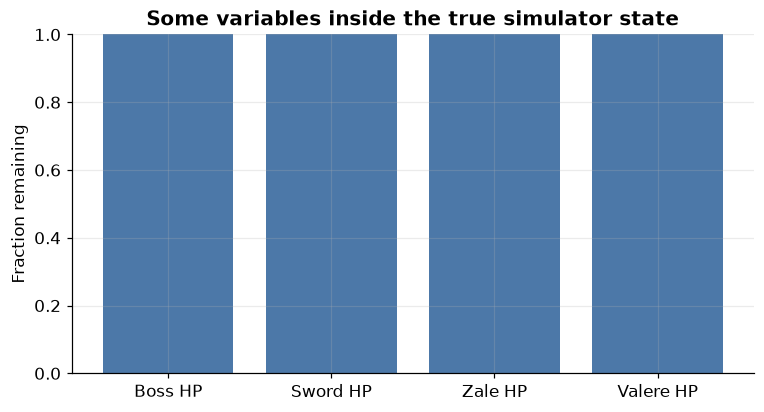

In [2]:
state = env.state
names = ["Boss HP","Sword HP","Zale HP","Valere HP"]
vals = [state.boss_hp/3995, state.sword_hp/800, state.zale_hp/300, state.valere_hp/300]

plt.figure(figsize=(8,4))
plt.bar(names, vals, color=COLORS["STATE"])
plt.ylim(0,1)
plt.ylabel("Fraction remaining")
plt.title("Some variables inside the true simulator state")
plt.show()

<div style="border-left:10px solid #17BECF;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#17BECF">OBSERVATION</div><div style="font-size:21px;font-weight:800;margin-top:4px">2. Observation is what gets handed out</div></div>

Our environment returns a numeric observation vector. The world can contain more structure than that vector shows.

Later we deliberately change what counts as the **state representation** used by the policy.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-el4" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">State ≠ observation</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">TRUE STATE</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el4)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">OBSERVATION FUNCTION</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el4)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">NUMERIC VECTOR</text>
</svg>
</div>


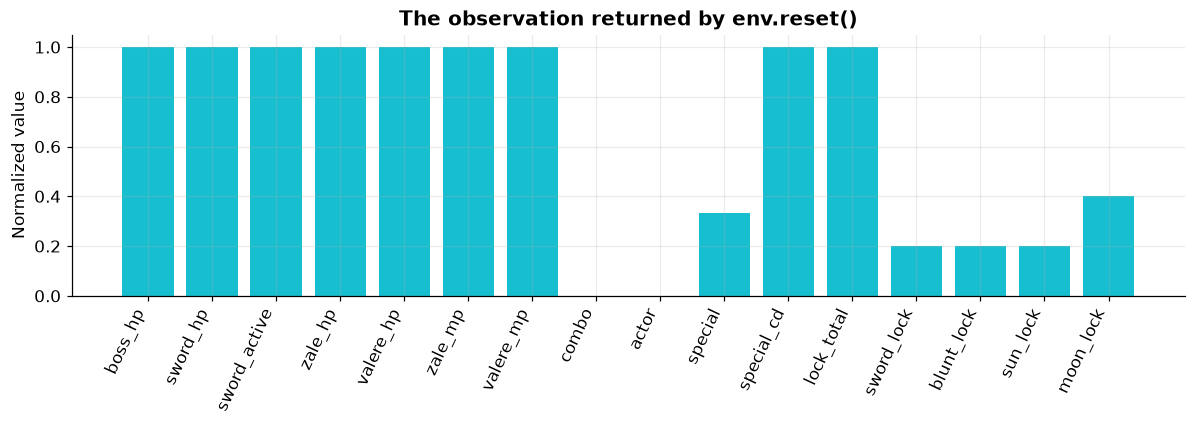

In [3]:
obs, _ = env.reset(seed=7)
labels = [
    "boss_hp","sword_hp","sword_active","zale_hp","valere_hp",
    "zale_mp","valere_mp","combo","actor","special","special_cd",
    "lock_total","sword_lock","blunt_lock","sun_lock","moon_lock"
]

plt.figure(figsize=(11,4))
plt.bar(labels, obs, color=COLORS["OBSERVATION"])
plt.xticks(rotation=65, ha="right")
plt.ylabel("Normalized value")
plt.title("The observation returned by env.reset()")
plt.tight_layout()
plt.show()

<div style="border-left:10px solid #0F766E;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#0F766E">POLICY</div><div style="font-size:21px;font-weight:800;margin-top:4px">3. Play it yourself — <b>you are the policy</b></div></div>

Click a legal move.

The simulator will apply the move, progress timers, possibly trigger Counter Slash or a charged move, and return the next observation and reward.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-el6" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Manual policy</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">OBSERVATION</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el6)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">YOUR BRAIN = π</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el6)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">CLICK ACTION</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el6)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#B279A2" stroke="#B279A2" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">env.step()</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el6)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#5B8FF9" stroke="#5B8FF9" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">NEW STATE</text>
</svg>
</div>


In [4]:
manual = ElderMistReplicaEnv(reward_mode="shaped")
manual.reset(seed=11)

out_widget = widgets.Output()
buttons = {a: widgets.Button(description=a.replace("_"," "), layout=widgets.Layout(width="175px"))
           for a in ACTIONS}
reset_button = widgets.Button(description="RESET FIGHT", button_style="warning")

def redraw_manual():
    with out_widget:
        clear_output(wait=True)
        fig = plot_state(manual, "YOU are choosing the next action")
        display(fig)
        plt.close(fig)
        print("Valid:", manual.valid_actions())
        print("Last:", manual.last_event)
    valid = set(manual.valid_actions())
    for name, b in buttons.items():
        b.disabled = name not in valid or manual._done()

def make_cb(name):
    def _cb(_):
        _, r, term, trunc, _ = manual.step(ACTION_TO_ID[name])
        redraw_manual()
        with out_widget:
            print(f"Reward from last transition: {r:+.3f}")
    return _cb

for name, b in buttons.items():
    b.on_click(make_cb(name))

def do_reset(_):
    manual.reset(seed=11)
    redraw_manual()
reset_button.on_click(do_reset)

display(widgets.VBox([
    widgets.HBox(list(buttons.values())[:4]),
    widgets.HBox(list(buttons.values())[4:]),
    reset_button,
    out_widget
]))
redraw_manual()

<div style="border-left:10px solid #B279A2;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#B279A2">TRANSITION</div><div style="font-size:21px;font-weight:800;margin-top:4px">4. Why did a move cause that result?</div></div>

The policy chooses only the **action**.

The environment's transition logic determines damage, lock breaking, counters, boss turns, Sword revival, and charged attacks.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-el8" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Action is not consequence</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION: SUNBALL</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el8)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#B279A2" stroke="#B279A2" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">TRANSITION RULES</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el8)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#B279A2" stroke="#B279A2" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SWORD HP ↓</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el8)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#B279A2" stroke="#B279A2" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BOSS HP ↓</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el8)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#5B8FF9" stroke="#5B8FF9" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">NEW OBS</text>
</svg>
</div>


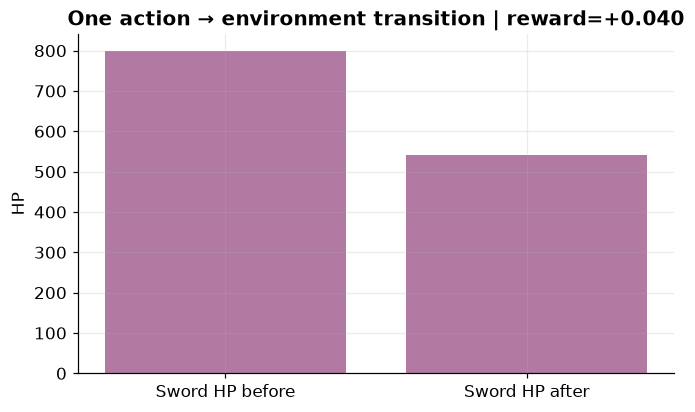

Zale: sunball_sword -> Sword -260, splash Boss -115 (no Counter Slash)


In [5]:
demo = ElderMistReplicaEnv()
demo.reset(seed=2)
before = demo.state.sword_hp
_, reward, _, _, _ = demo.step(ACTION_TO_ID["sunball_sword"])
after = demo.state.sword_hp

plt.figure(figsize=(7,4))
plt.bar(["Sword HP before","Sword HP after"], [before, after], color=COLORS["TRANSITION"])
plt.ylabel("HP")
plt.title(f"One action → environment transition | reward={reward:+.3f}")
plt.show()

print(demo.last_event)

<div style="border-left:10px solid #0F766E;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#0F766E">POLICY</div><div style="font-size:21px;font-weight:800;margin-top:4px">5. A rule policy is still a policy</div></div>

This baseline contains readable `if/else` logic.

If it chooses Sunball, we can explain the move because **we explicitly wrote the reason into the policy**.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-el10" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Policy without learning</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">STATE</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el10)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">IF/ELSE RULES</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el10)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">MOVE</text>
</svg>
</div>


Chosen move: sunball_sword
WHY: The Sword is active. Directly hitting Elder Mist's body would trigger Counter Slash. Sunball targets the Sword while splashing damage onto the boss, so this baseline prefers it.


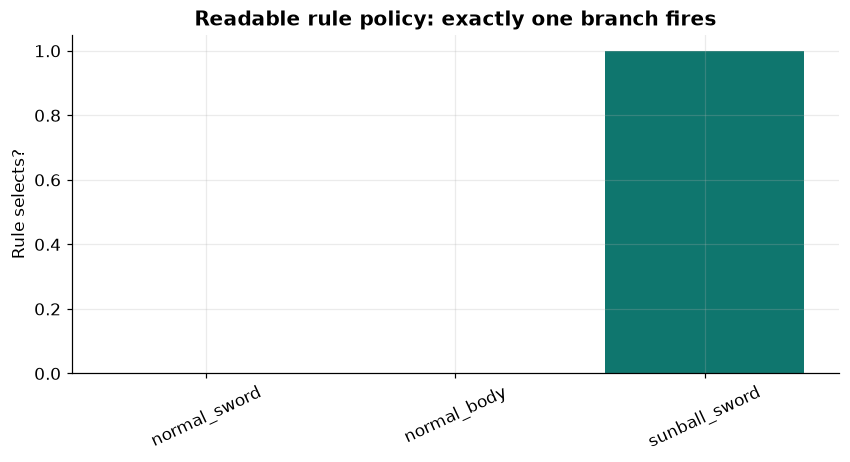

In [6]:
demo = ElderMistReplicaEnv()
demo.reset(seed=8)
move, reason = explain_sensible_rule_policy(demo)

print("Chosen move:", move)
print("WHY:", reason)

choices = demo.valid_actions()
scores = [1 if x == move else 0 for x in choices]
plt.figure(figsize=(9,4))
plt.bar(choices, scores, color=COLORS["POLICY"])
plt.xticks(rotation=25)
plt.ylabel("Rule selects?")
plt.title("Readable rule policy: exactly one branch fires")
plt.show()

<div style="border-left:10px solid #54A24B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#54A24B">REWARD</div><div style="font-size:21px;font-weight:800;margin-top:4px">6. Compare random behavior with a sensible hand-written policy</div></div>

This is **evaluation**, not learning.

We run many fresh episodes and measure win rate and Counter Slashes.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-el12" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Evaluate behavior</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el12)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#8B5CF6" stroke="#8B5CF6" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">100 FRESH FIGHTS</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el12)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">WIN RATE / COUNTERS</text>
</svg>
</div>


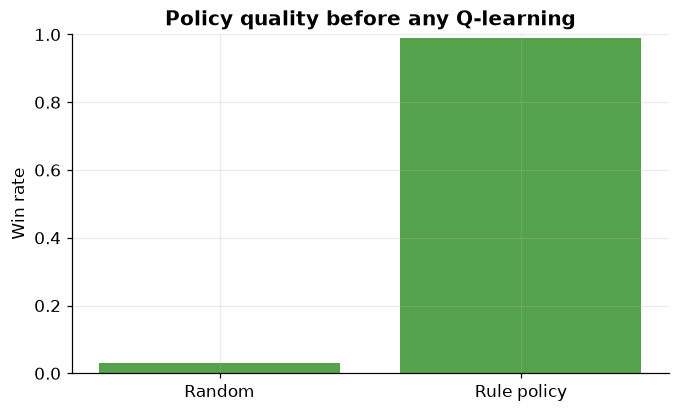

Average Counter Slashes — random: 3.97
Average Counter Slashes — rule: 0.0


In [7]:
def evaluate_policy(policy, seeds):
    rows = []
    for seed in seeds:
        e = ElderMistReplicaEnv()
        o, _ = e.reset(seed=seed)
        while True:
            a = policy(e, o)
            o, r, term, trunc, _ = e.step(a)
            if term or trunc:
                break
        rows.append({
            "win": int(e.state.boss_hp <= 0),
            "counter_slashes": e.state.counter_slashes,
            "turns": e.state.turn
        })
    return pd.DataFrame(rows)

def random_policy(e, o):
    return ACTION_TO_ID[np.random.choice(e.valid_actions())]

rand_df = evaluate_policy(random_policy, range(100))
rule_df = evaluate_policy(sensible_rule_policy, range(100))

plt.figure(figsize=(7,4))
plt.bar(["Random","Rule policy"], [rand_df.win.mean(), rule_df.win.mean()], color=COLORS["REWARD"])
plt.ylim(0,1)
plt.ylabel("Win rate")
plt.title("Policy quality before any Q-learning")
plt.show()

print("Average Counter Slashes — random:", rand_df.counter_slashes.mean())
print("Average Counter Slashes — rule:", rule_df.counter_slashes.mean())

<div style="border-left:10px solid #ECA82C;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#ECA82C">Q</div><div style="font-size:21px;font-weight:800;margin-top:4px">7. Q-learning: learning lives in the Q-table</div></div>

For every represented state and legal action, store an estimate:

`Q(state, action) ≈ expected future return`.

Experience changes those numbers.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-el14" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">The learner&#x27;s memory</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">STATE</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el14)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el14)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">REWARD</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el14)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#5B8FF9" stroke="#5B8FF9" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">NEXT STATE</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el14)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#ECA82C" stroke="#ECA82C" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">Q UPDATE</text>
</svg>
</div>


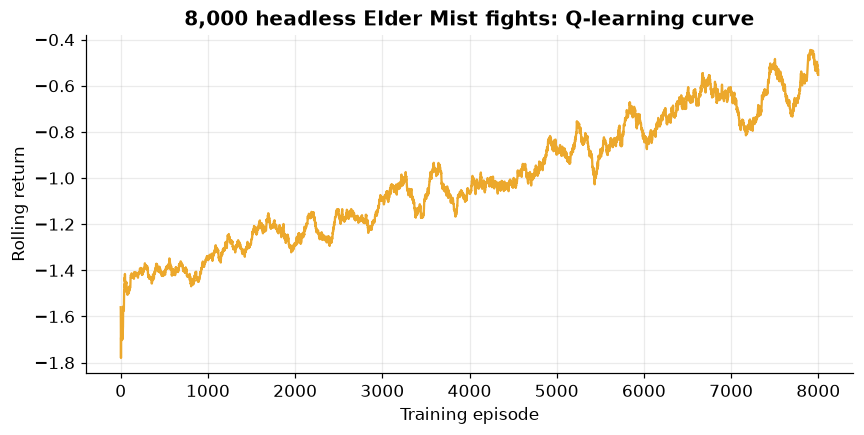

In [8]:
q, train_rows = train_q(
    lambda: ElderMistReplicaEnv(representation="full", reward_mode="shaped"),
    episodes=8000,
    seed=42
)
train_df = pd.DataFrame(train_rows)

plt.figure(figsize=(9,4))
plt.plot(train_df["episode"], train_df["return"].rolling(200, min_periods=1).mean(), color=COLORS["Q"])
plt.xlabel("Training episode")
plt.ylabel("Rolling return")
plt.title("8,000 headless Elder Mist fights: Q-learning curve")
plt.show()

<div style="border-left:10px solid #ECA82C;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#ECA82C">Q</div><div style="font-size:21px;font-weight:800;margin-top:4px">8. Why did the learned policy choose <i>this</i> move?</div></div>

Unlike the rule policy, there may be no English `if Sword active → Sunball` rule.

The Q-policy chooses the legal action with the largest learned Q-value for the current represented state.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-el16" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Q-policy decision</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">CURRENT REPRESENTATION</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el16)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#ECA82C" stroke="#ECA82C" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">LOOK UP Q VALUES</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el16)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#2F80ED" stroke="#2F80ED" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ARGMAX</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el16)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION</text>
</svg>
</div>


Represented state: (0, 4, 4, 5, 1, 5, 1, 3, 5, 0, 3, 3, 0)
Chosen: sunball_sword


,action_id,action,q_value
0,1,sunball_sword,0.141807
1,0,normal_sword,0.114826
2,2,normal_body,-0.055854


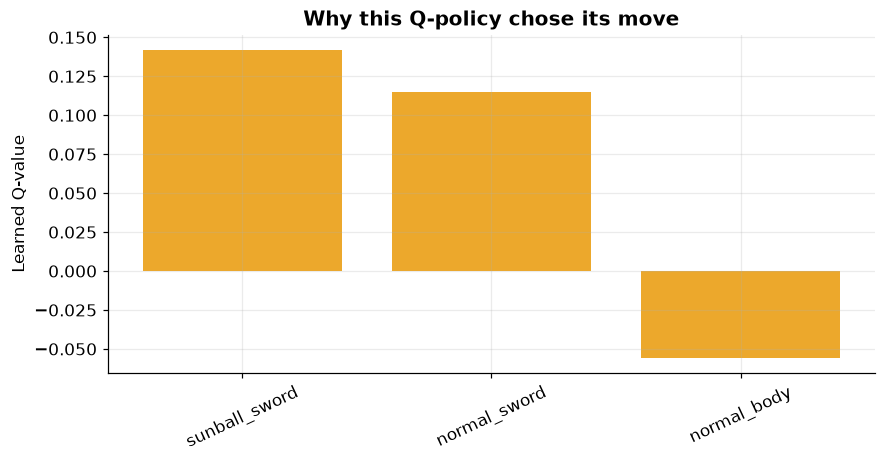

In [9]:
inspect_env = ElderMistReplicaEnv(representation="full")
inspect_env.reset(seed=123)
exp = explain_q_choice(q, inspect_env)
qdf = pd.DataFrame(exp["ranked_actions"])

print("Represented state:", exp["represented_state"])
print("Chosen:", exp["chosen_action"])
display(qdf)

plt.figure(figsize=(9,4))
plt.bar(qdf["action"], qdf["q_value"], color=COLORS["Q"])
plt.xticks(rotation=25)
plt.ylabel("Learned Q-value")
plt.title("Why this Q-policy chose its move")
plt.show()

<div style="border-left:10px solid #0F766E;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#0F766E">POLICY</div><div style="font-size:21px;font-weight:800;margin-top:4px">9. Watch one learned-policy fight unfold</div></div>

Now freeze learning and act greedily from the Q-table.

The following plot shows Elder Mist HP over the sequence of actions.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-el18" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Evaluation rollout</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#ECA82C" stroke="#ECA82C" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">LEARNED Q TABLE</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el18)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#2F80ED" stroke="#2F80ED" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">GREEDY ACTION</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el18)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BATTLE</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el18)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#8B5CF6" stroke="#8B5CF6" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">REPEAT</text>
</svg>
</div>


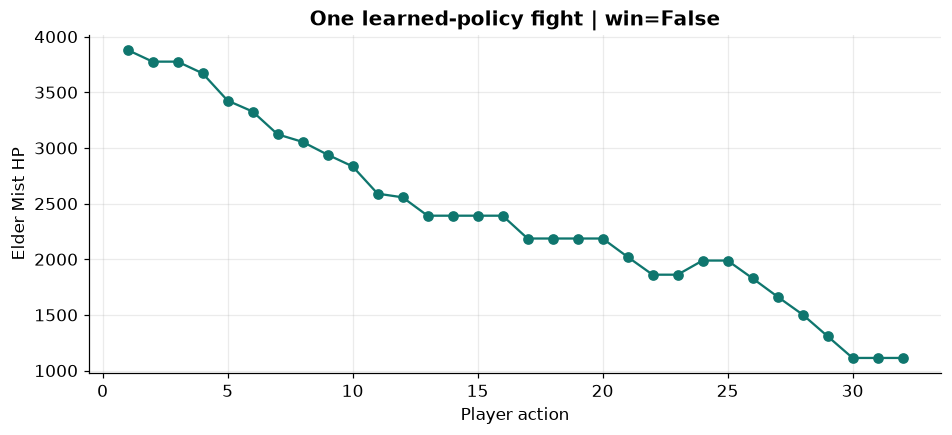

,turn,boss_hp,sword_hp,counter_slashes,action
0,1,3880,540,0,sunball_sword
1,2,3775,305,0,crescent_sword
2,3,3775,120,0,normal_sword
3,4,3670,0,0,crescent_sword
4,5,3425,0,0,sunball_sword
5,6,3327,0,0,crescent_sword
6,7,3122,0,0,normal_body
7,8,3054,489,0,normal_body
8,9,2939,229,0,sunball_sword
9,10,2834,0,0,crescent_sword


In [10]:
e = ElderMistReplicaEnv(representation="full")
o, _ = e.reset(seed=321)
rows = []

while True:
    a = q_policy(q, e)
    action_name = ACTIONS[a]
    o, r, term, trunc, _ = e.step(a)
    rows.append({
        "turn": e.state.turn,
        "boss_hp": e.state.boss_hp,
        "sword_hp": e.state.sword_hp,
        "counter_slashes": e.state.counter_slashes,
        "action": action_name
    })
    if term or trunc:
        break

roll = pd.DataFrame(rows)

plt.figure(figsize=(10,4))
plt.plot(roll["turn"], roll["boss_hp"], marker="o", color=COLORS["POLICY"])
plt.xlabel("Player action")
plt.ylabel("Elder Mist HP")
plt.title(f"One learned-policy fight | win={e.state.boss_hp <= 0}")
plt.show()

display(roll.head(20))

<div style="border-left:10px solid #1F3A93;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#1F3A93">REPRESENTATION</div><div style="font-size:21px;font-weight:800;margin-top:4px">10. State representation experiment</div></div>

Now hold the environment and learner fixed.

Only change what the policy is allowed to distinguish:

- FULL
- NO SWORD
- NO LOCKS
- MINIMAL

This is the exact logic behind testing screenshot vs accessibility tree vs history.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-el20" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Controlled ablation</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SAME WORLD</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el20)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">DIFFERENT REPRESENTATION</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el20)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SAME LEARNER</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el20)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">COMPARE</text>
</svg>
</div>


,representation,win_rate,avg_counters
0,full,0.166667,0.220000
1,no_sword,0.353333,0.766667
2,no_locks,0.640000,0.453333
3,minimal,0.880000,0.240000


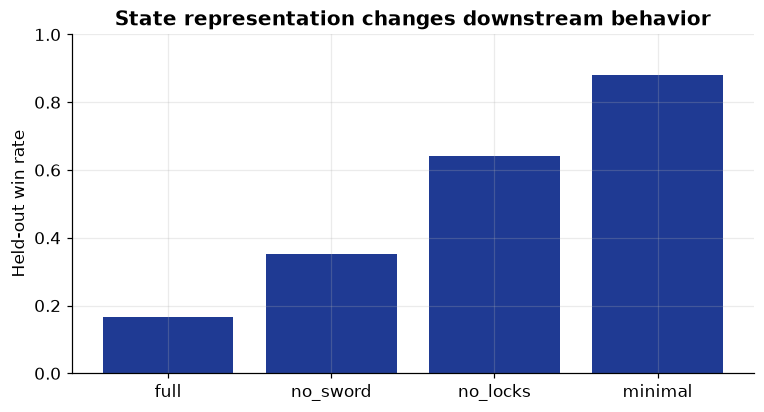

In [11]:
reps = ["full","no_sword","no_locks","minimal"]
summary = []

for rep in reps:
    qrep, _ = train_q(
        lambda rep=rep: ElderMistReplicaEnv(representation=rep, reward_mode="shaped"),
        episodes=5000,
        seed=100
    )
    wins = []
    counters = []
    for seed in range(10000,10150):
        er = ElderMistReplicaEnv(representation=rep, reward_mode="shaped")
        o,_ = er.reset(seed=seed)
        while True:
            a = q_policy(qrep, er)
            o,r,term,trunc,_ = er.step(a)
            if term or trunc: break
        wins.append(int(er.state.boss_hp <= 0))
        counters.append(er.state.counter_slashes)
    summary.append((rep, np.mean(wins), np.mean(counters)))

summary_df = pd.DataFrame(summary, columns=["representation","win_rate","avg_counters"])
display(summary_df)

plt.figure(figsize=(8,4))
plt.bar(summary_df["representation"], summary_df["win_rate"], color=COLORS["REPRESENTATION"])
plt.ylim(0,1)
plt.ylabel("Held-out win rate")
plt.title("State representation changes downstream behavior")
plt.show()

<div style="border-left:10px solid #334155;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#334155">ENVIRONMENT</div><div style="font-size:21px;font-weight:800;margin-top:4px">11. The research interpretation</div></div>

If hiding Sword state hurts performance, the reason is not “less telemetry sounds bad.”

The reason is that two strategically different worlds become indistinguishable to the policy.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-el22" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">State aliasing</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">WORLD A: SWORD UP</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el22)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SAME REPRESENTATION?</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el22)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">WORLD B: SWORD DOWN</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el22)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BAD ALIASING</text>
</svg>
</div>


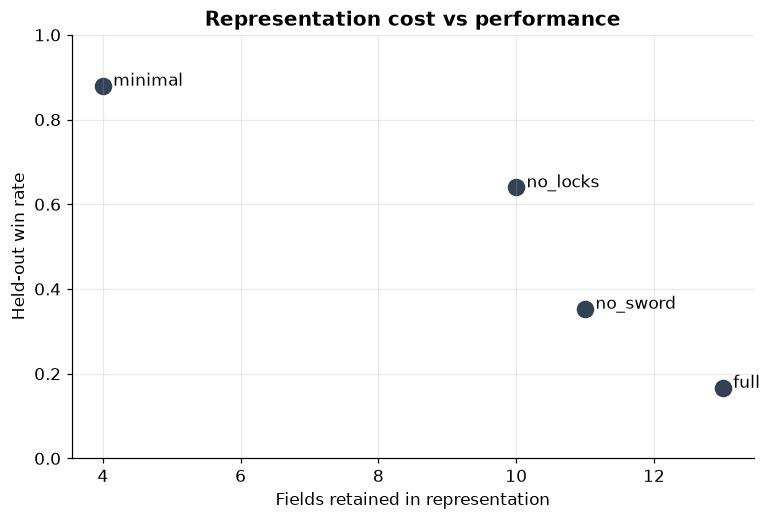

In [12]:
rep_size = {"full":13, "no_sword":11, "no_locks":10, "minimal":4}
summary_df["fields"] = summary_df["representation"].map(rep_size)

plt.figure(figsize=(8,5))
plt.scatter(summary_df["fields"], summary_df["win_rate"], s=110, color=COLORS["ENVIRONMENT"])
for _, r in summary_df.iterrows():
    plt.text(r["fields"]+0.15, r["win_rate"], r["representation"])
plt.xlabel("Fields retained in representation")
plt.ylabel("Held-out win rate")
plt.ylim(0,1)
plt.title("Representation cost vs performance")
plt.show()

<div style="border-left:10px solid #64748B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#64748B">KEY IDEA</div><div style="font-size:21px;font-weight:800;margin-top:4px">Once this clicks → POMDP</div></div>

So far the agent is handed a representation each turn.

Next we deliberately hide truth and give noisy evidence. Then the agent needs **history** and a **belief** about hidden state.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-el24" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Next: partial observability</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">HIDDEN TRUE STATE</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el24)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">NOISY OBSERVATIONS</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el24)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">HISTORY</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el24)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#A3A01B" stroke="#A3A01B" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BELIEF</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-el24)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY</text>
</svg>
</div>
